# Предобработка данных и регрессия на датасете «House Prices»
 
**Дисциплина:** Машинное обучение и ИИ   
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices - Advanced Regression Techniques  
 
**Выполнила:** Жданова Анна Александровна  
**Группа:** ПКТб-23-1   
**Преподаватель:** Спирин И.С.    

**Ссылка на репозиторий:** https://github.com/ZhdanovaAnna/ml-course-zhdanova

**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  

**Дата сдачи:** 13.10.2026 

## 2. Введение

В данной работе рассматривается задача машинного обучения, связанная с прогнозированием стоимости жилой недвижимости. Для построения моделей используется датасет ***House Prices - Advanced Regression Techniques***, содержащий характеристики домов и фактические цены их продажи.

### Постановка задачи 
Необходимо построить модель регрессии, которая на основе характеристик объекта недвижимости будет предсказывать его цену продажи ***SalePrice***.

### Что такое ML-проект для регрессии?
Полный ML-проект включает загрузку данных, разведочный анализ (EDA), обработку пропусков и выбросов, создание новых признаков, обучение моделей, оценку качества и интерпретацию полученных результатов.

### Почему это регрессия, а не классификация?
Регрессия используется потому, что целевая переменная представляет собой непрерывную числовую величину. В отличие от классификации, где модель определяет категорию объекта, регрессионная модель прогнозирует конкретное числовое значение.

### Какая метрика важнее в этой задаче?
В качестве основной метрики рассматривается ***RMSE***, поскольку она позволяет оценить типичный масштаб ошибки в исходных единицах целевой переменной и сильнее штрафует большие ошибки. Дополнительно используются ***MAE и $R^2$***, которые позволяют оценить абсолютную ошибку и объясняющую способность модели.

### Цель работы - освоить полный цикл построения регрессионной модели на примере датасета House Prices.

Для достижения цели необходимо решить следующие задачи:

1. Провести разведочный анализ данных и изучить распределение целевой переменной.

2. Выполнить предобработку данных, обработать пропуски и выбросы, создать новые признаки.

3. Обучить и сравнить модели ***Linear Regression, Ridge, Lasso и ElasticNet***.

4. Оценить качество моделей с помощью ***RMSE, MAE и $R^2$***.

5. Интерпретировать коэффициенты моделей и выделить наиболее значимые признаки.

6. Реализовать функцию ***predict_price()*** для прогнозирования стоимости дома.

7. Сохранить обученные модели и продемонстрировать их загрузку из GitHub.

## 3. Теоретическая часть
### 3.1. Регрессионный анализ

***Регрессия*** - это задача машинного обучения с учителем, при которой модель устанавливает зависимость между входными признаками объекта и непрерывной целевой переменной.

В рассматриваемом проекте входными признаками являются характеристики дома: площадь, год постройки, качество отделки, число комнат, состояние объекта, тип района и другие параметры. Целевой переменной является цена продажи **SalePrice**.

В общем виде модель можно представить следующим образом:

$$
\hat{y}=f(X),
$$

где $X$ - набор характеристик объекта, $f$ - обученная модель, а $\hat{y}$ - предсказанная цена.

Качество регрессии зависит не только от выбранного алгоритма, но и от полноты данных, корректности предобработки, информативности признаков и способности модели обобщать закономерности на ранее не встречавшихся объектах.

### 3.2. Линейная регрессия

***Линейная регрессия*** предполагает, что целевая переменная может быть представлена как линейная комбинация признаков:

$$
\hat{y}=\beta_0+\beta_1x_1+\beta_2x_2+\ldots+\beta_px_p,
$$

где $\beta_0$ - свободный член, $\beta_j$ - коэффициент соответствующего признака, а $p$ - количество признаков.

Преимущество линейной регрессии заключается в простоте, высокой скорости обучения и относительной прозрачности интерпретации. Однако при большом количестве коррелирующих признаков коэффициенты могут становиться нестабильными. Кроме того, обычная линейная регрессия не выполняет автоматический отбор признаков и может чувствительно реагировать на отдельные наблюдения с большими ошибками.

### 3.3. Регуляризация

***Регуляризация*** - это способ ограничить сложность модели за счёт добавления штрафа к функции потерь. Она помогает уменьшить переобучение и повысить устойчивость модели.

**Ridge-регрессия** использует L2-регуляризацию. К функции ошибки добавляется сумма квадратов коэффициентов:

$$
L_{\text{Ridge}}=MSE+\alpha\sum_{j=1}^{p}\beta_j^2.
$$

Параметр $\alpha$ определяет силу регуляризации. При увеличении этого параметра коэффициенты сильнее уменьшаются по модулю, однако обычно не становятся строго равными нулю.

**Lasso-регрессия** использует L1-регуляризацию:

$
L_{\text{Lasso}}=MSE+\alpha\sum_{j=1}^{p}|\beta_j|.
$

Особенность Lasso заключается в том, что некоторые коэффициенты могут становиться равными нулю. Благодаря этому модель способна выполнять отбор признаков и формировать более компактное представление зависимости цены от характеристик дома.

**ElasticNet** сочетает L1- и L2-регуляризацию. Такой подход объединяет свойства **Ridge и Lasso** и может быть полезен при большом количестве признаков, в том числе коррелирующих между собой.

В данной работе сила регуляризации подбирается с помощью **GridSearchCV** на обучающих данных. Это позволяет выбирать параметры не только по одному разбиению, но и на основе результатов перекрёстной проверки.

### 3.4. Предобработка данных

Реальные наборы данных могут содержать пропущенные значения, числовые признаки с разными масштабами и категориальные переменные, представленные текстом. Перед обучением такие данные необходимо привести к формату, который корректно обрабатывается алгоритмом.

Пропуски в числовых признаках можно заменять медианой, а в категориальных - наиболее часто встречающимся значением. Медиана менее чувствительна к экстремальным значениям, чем среднее арифметическое.

Для масштабирования числовых признаков применяется стандартизация:

$$
z=\frac{x-\mu}{\sigma},
$$

где $\mu$ - среднее значение признака на обучающих данных, а $\sigma$ - стандартное отклонение.

Категориальные признаки преобразуются с помощью **One-Hot Encoding**. В результате исходная категория представляется набором бинарных столбцов. Такой способ позволяет использовать категориальную информацию в моделях, ожидающих числовые входные данные.

Все этапы предобработки объединяются в конвейер **Pipeline**. Это обеспечивает единообразную обработку обучающих и новых данных и уменьшает риск утечки информации между обучающей и проверочной выборками.

### 3.5. Feature Engineering

***Feature Engineering*** - это процесс создания новых признаков на основе существующих данных. Дополнительные признаки могут лучше отражать свойства объекта и помогать модели выявлять закономерности.

Для датасета недвижимости можно рассмотреть возраст дома на момент продажи, продолжительность периода после реконструкции, общую площадь жилых помещений и наличие отдельных элементов благоустройства.

Новые признаки должны рассчитываться только на основе информации, доступной на момент прогнозирования. Например, возраст дома корректнее вычислять как разницу между годом продажи и годом постройки, а не между годом постройки и текущим календарным годом. Это делает признак согласованным с историческим моментом продажи.

Создание дополнительных признаков не гарантирует улучшения качества. Их полезность должна проверяться экспериментально на отложенной выборке.

### 3.6. Метрики качества регрессии

Для оценки моделей используются три основные метрики.

***Mean Squared Error (MSE)*** - средний квадрат разности между фактическими и предсказанными значениями:

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2.
$$

Большие ошибки оказывают существенное влияние на **MSE**, поскольку разности возводятся в квадрат.

***Root Mean Squared Error (RMSE)*** - квадратный корень из MSE:

$$
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}.
$$

**RMSE** выражается в тех же единицах, что и целевая переменная, если расчёт выполняется на исходной шкале цены. Чем меньше **RMSE**, тем ниже типичный уровень ошибки с учётом усиленного штрафа за крупные отклонения.

***Mean Absolute Error (MAE)*** - среднее абсолютное отклонение прогноза от фактического значения:

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|.
$$

**MAE** проще интерпретировать как среднюю абсолютную ошибку. Эта метрика менее чувствительна к отдельным большим отклонениям, чем **RMSE**.

***Коэффициент детерминации (R^2)*** показывает, насколько хорошо модель описывает вариацию целевой переменной относительно базового прогноза средним значением:

$$
R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}i)^2}
{\sum{i=1}^{n}(y_i-\bar{y})^2}.
$$

Чем ближе **$R^2$** к единице, тем лучше модель объясняет вариацию целевой переменной на рассматриваемой выборке. Отрицательное значение также возможно и означает, что модель на этой выборке работает хуже базового прогноза средним.

В рамках работы метрики вычисляются как на логарифмированной шкале цены, используемой при обучении, так и на исходной шкале в денежных единицах. Это позволяет оценить математическое качество моделей и понятнее интерпретировать ошибки прогнозирования.

### 3.7. Кросс-валидация

***Кросс-валидация*** - это метод оценки качества модели на нескольких разбиениях данных. При **$k$-блочной** кросс-валидации выборка делится на $k$ частей. На каждом шаге модель обучается на части данных и проверяется на оставшейся части. Затем результаты усредняются.

**GridSearchCV** перебирает заданные значения гиперпараметров и оценивает их с помощью перекрёстной проверки. В данном проекте этот механизм применяется для настройки **Ridge, Lasso и ElasticNet**.

Кросс-валидация помогает снизить зависимость выбора параметров от одного случайного разбиения. При этом окончательная оценка модели должна выполняться на отдельной тестовой части, которая не использовалась при настройке гиперпараметров.

### 3.8. Схема исследования
|Этап |	Содержание        |	Результат                           |
|-----|-------------------|-------------------------------------|
|  1  | Загрузка данных	  | Исходная таблица                    |
|  2  | EDA	              | Понимание структуры и зависимостей  |
|  3  | Предобработка	  | Подготовленные признаки             |
|  4  | Обучение	      | Четыре регрессионные модели         | 
|  5  | Оценка	          | Таблица метрик                      |
|  6  | Интерпретация	  | Анализ коэффициентов                |
|  7  | Сохранение	      | Файлы моделей и метаданные          |
|  8  | Проверка загрузки | Возможность повторного использования|

## 4. Описание данных

### 4.1. Источник данных

Используется датасет **House Prices - Advanced Regression Techniques** с Kaggle: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

### 4.2. Структура данных

В комплект входят **train.csv** с целевой переменной **SalePrice и test.csv**, в котором целевая переменная отсутствует. В стандартной версии обучающая выборка содержит 1 460 объектов и 81 столбец, тестовая - 1 459 объектов и 80 столбцов. Фактические размеры проверяются кодом, поскольку локальные файлы могут отличаться.

Целевая переменная - ***SalePrice***, цена продажи дома в долларах. Признаки описывают качество и состояние дома, площади, год постройки, гараж, подвал, район и другие характеристики.

### 4.3. Основные группы признаков

- **Качество и состояние:** OverallQua, OverallCond, YearBuilt, YearRemodAdd.
- **Площади:** GrLivArea, TotalBsmtSF, 1stFlrSF, 2ndFlrSF.
- **Оснащение:** GarageCars, Fireplaces, PoolArea, характеристики ванных комнат.
- **Категориальные признаки:** Neighborhood, HouseStyle, SaleCondition и другие.

Идентификатор ***Id*** используется только для идентификации объекта и не подаётся в модель. Далее будут проверены описательная статистика, пропуски и асимметрия **SalePrice**.

In [1]:
# Импорт библиотек 
import os
import time
import json
import joblib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Фиксирование случайного состояния для воспроизводимого разбиения
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

### Загрузка данных

Целевая переменная присутствует только в обучающем файле.

In [2]:
# Загружаем исходные обучающую и тестовую выборки из папки data
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

### Первичный осмотр

In [3]:
# Вывод размера обеих таблиц для проверки загрузки
print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)

# Первые строки обучающей выборки
display(train_df.head())

# Типы столбцов и число непустых значений
train_df.info()

# Описательная статистику числовых признаков
display(train_df.describe())

# Оценка асимметрии и эксцесса распределения
print("Асимметрия:", train_df["SalePrice"].skew())
print("Эксцесс:", train_df["SalePrice"].kurtosis())

Размер train: (1460, 81)
Размер test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


Асимметрия: 1.8828757597682129
Эксцесс: 6.536281860064529


### Вывод по разделу

По стандартной версии Kaggle House Prices средняя цена составляет около 180 921 доллара, медиана - около 163 000 долларов, а распределение **SalePrice** имеет выраженную правую асимметрию. Эти ориентиры необходимо сопоставлять с фактическими значениями, рассчитанными в предыдущей ячейке.

В данных присутствуют числовые и категориальные характеристики недвижимости. До обучения важно исследовать пропуски, распределения и экстремальные значения, а также исключить идентификатор из признакового пространства.

## 5. Подготовка данных и EDA

На этапе разведочного анализа изучаются пропуски, распределение целевой переменной, корреляции числовых признаков, связь площади и цены, а также потенциальные выбросы. Затем создаются дополнительные признаки и выполняется подготовка данных для моделей.

,Пропуски,"Пропуски, %"
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


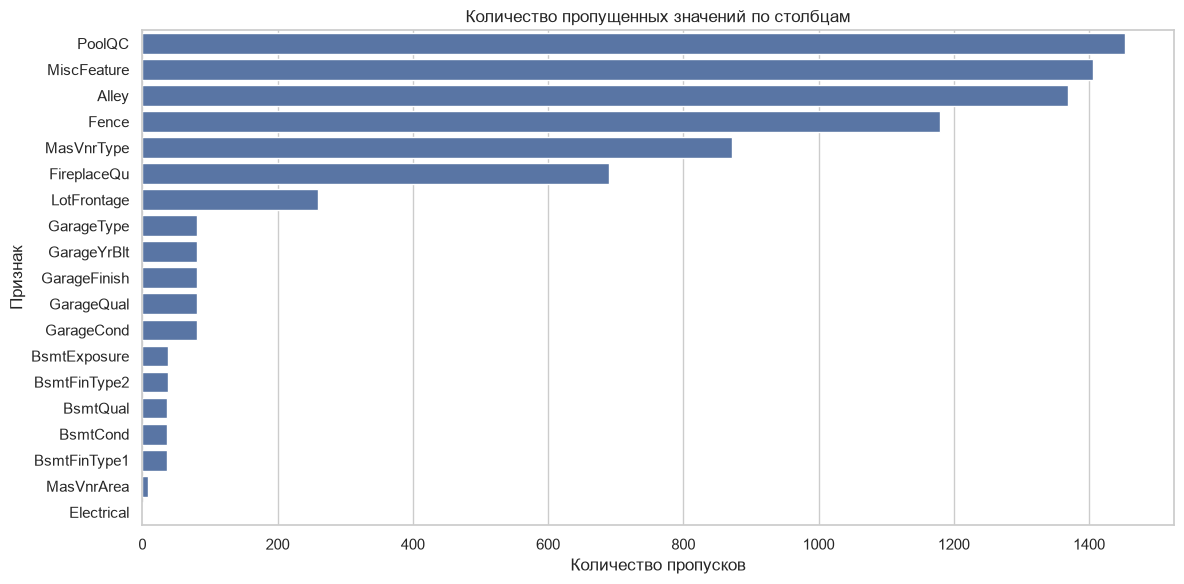

In [4]:
# Количество пропусков по каждому столбцу
missing_count = train_df.isnull().sum()

# Количество пропусков в процентах
missing_percent = missing_count / len(train_df) * 100

# Результаты в одной таблице.
missing_table = pd.DataFrame({
    "Пропуски": missing_count,
    "Пропуски, %": missing_percent
})

# Только столбцы, в которых есть пропуски
missing_table = missing_table[missing_table["Пропуски"] > 0]

# Сортировка столбцов по количеству пропусков
missing_table = missing_table.sort_values("Пропуски", ascending=False)

# Таблица пропусков.
display(missing_table)

# График количества пропусков в наиболее проблемных столбцах
if not missing_table.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing_table["Пропуски"].head(25),
        y=missing_table.index[:25]
    )
    plt.title("Количество пропущенных значений по столбцам")
    plt.xlabel("Количество пропусков")
    plt.ylabel("Признак")
    plt.tight_layout()
    plt.show()

### Результат анализа
В соответствующих **категориальных признаках** отсутствие может быть представлено отдельной категорией **None**. 

Для **числовых характеристик**, где отсутствие обычно означает нулевое значение, допускается заполнение нулём. 

Если пропуск означает неизвестное измерение, например для ***LotFrontage***, разумно использовать медиану, в том числе медиану по району, когда для этого достаточно данных.

### 5.2. Распределение целевой переменной

Асимметрия SalePrice: 1.8828757597682129
Асимметрия SalePrice_log: 0.12134661989685333


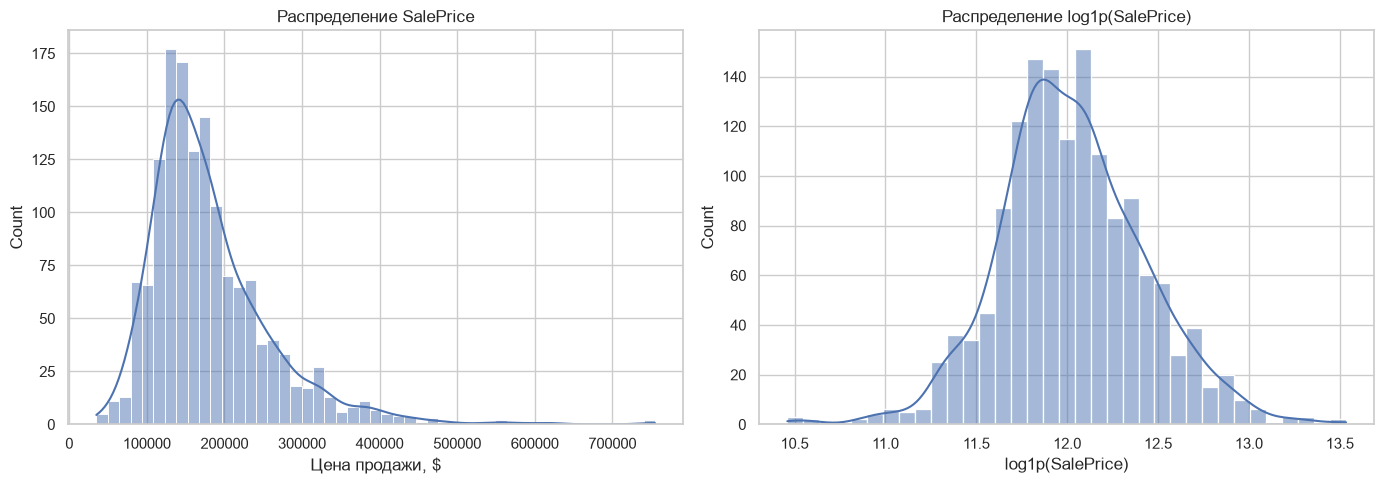

In [5]:
# Логарифмированна копия целевой переменной.
train_df["SalePrice_log"] = np.log1p(train_df["SalePrice"])

# Вывод асимметрии до и после преобразования.
print("Асимметрия SalePrice:", train_df["SalePrice"].skew())
print("Асимметрия SalePrice_log:", train_df["SalePrice_log"].skew())

# Сравнение распределения исходной и преобразованной цены.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма исходной цены.
sns.histplot(train_df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Распределение SalePrice")
axes[0].set_xlabel("Цена продажи, $")

# Гистограмма логарифмированной цены.
sns.histplot(train_df["SalePrice_log"], kde=True, ax=axes[1])
axes[1].set_title("Распределение log1p(SalePrice)")
axes[1].set_xlabel("log1p(SalePrice)")

# Выравнивание элементов и вывод графиков.
plt.tight_layout()
plt.show()

### Вывод по графику

Необходимо сравнить форму двух распределений. 

Если **логарифмирование уменьшило** правую асимметрию, это подтверждает целесообразность преобразования целевой переменной для рассматриваемых линейных моделей.

### 5.3. Корреляционная матрица

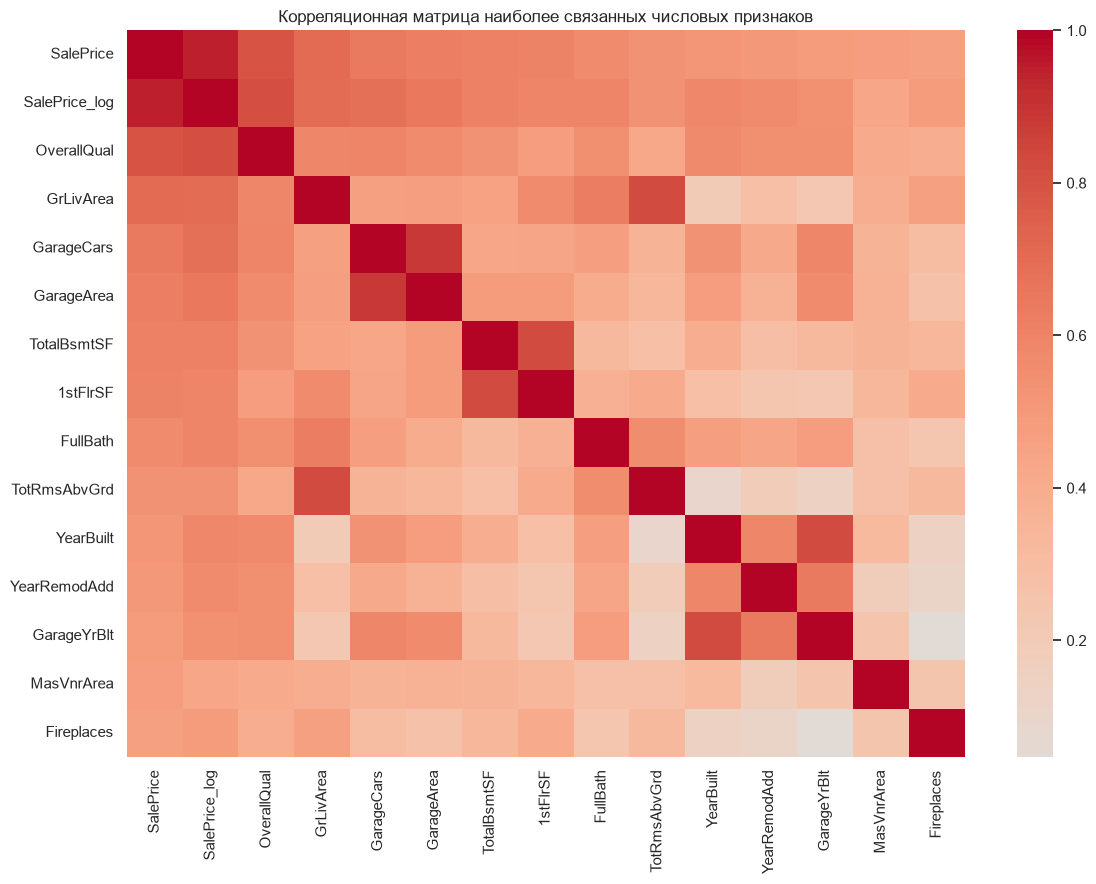

In [6]:
# Выбор только числовых признаков обучающей выборки
numeric_data = train_df.select_dtypes(include=np.number)

# Рассчёт корреляции между числовыми признаками
corr_matrix = numeric_data.corr()

# Выбор признаков, наиболее связанные с SalePrice
top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False).head(15)

# Тепловая карту корреляций выбранных признаков
plt.figure(figsize=(12, 9))
sns.heatmap(
    numeric_data[top_corr.index].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Корреляционная матрица наиболее связанных числовых признаков")
plt.tight_layout()
plt.show()

### Вывод по графику
Корреляция показывает линейную связь, но не доказывает причинность. 

В стандартной версии датасета сильнее всего с ценой связаны ***OverallQual*** (примерно 0,79), ***GrLivArea*** (примерно 0,71) и ***GarageCars*** (примерно 0,64).

### 5.4. Жилая площадь и стоимость

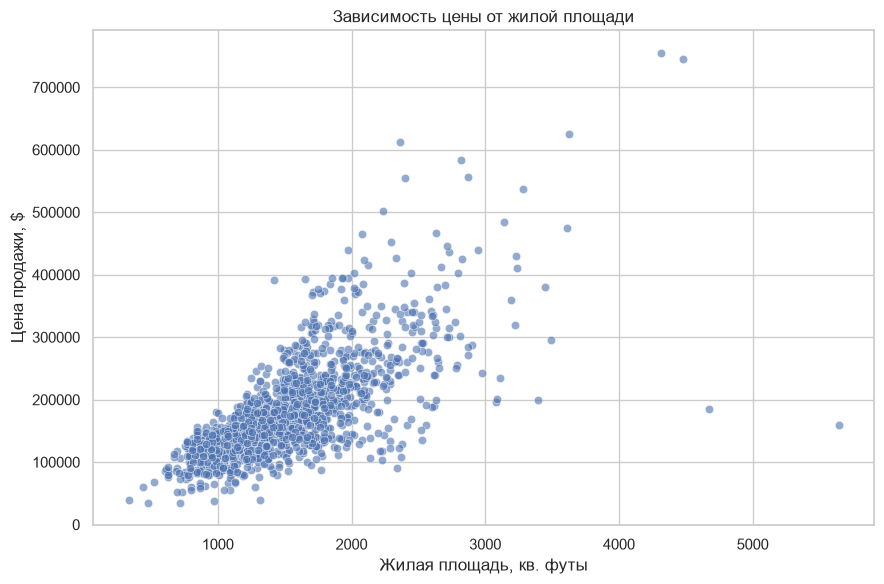

In [7]:
# Диаграмма рассеяния площади и цены продажи
plt.figure(figsize=(9, 6))
sns.scatterplot(data=train_df, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.title("Зависимость цены от жилой площади")
plt.xlabel("Жилая площадь, кв. футы")
plt.ylabel("Цена продажи, $")
plt.tight_layout()
plt.show()

### Вывод по графику

Для ***GrLivArea*** ожидается положительная связь с ***SalePrice***: более просторные дома в среднем продаются дороже. 

При этом разброс точек означает, что площадь **не объясняет цену полностью** - на стоимость также влияют качество, район, состояние и другие характеристики.

### 5.5. Boxplot площади по качеству дома

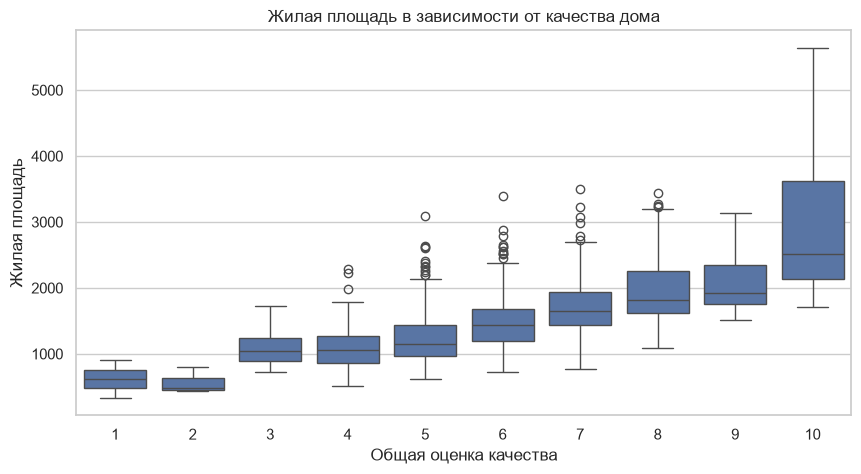

In [8]:
# Сравнение распределения жилой площади для разных оценок качества
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df, x="OverallQual", y="GrLivArea")
plt.xlabel("Общая оценка качества")
plt.ylabel("Жилая площадь")
plt.title("Жилая площадь в зависимости от качества дома")
plt.show()

### Вывод по качеству и площади

Сопоставление коробчатых диаграмм позволяет проверить, растёт ли типичная жилая площадь вместе с ***OverallQual***. 

Разброс внутри одного уровня качества показывает, что дома одинакового качества могут **заметно различаться по площади**; единичные точки за пределами «усов» являются потенциальными **выбросами**, а не автоматически ошибочными данными.

### 5.6. График пропусков

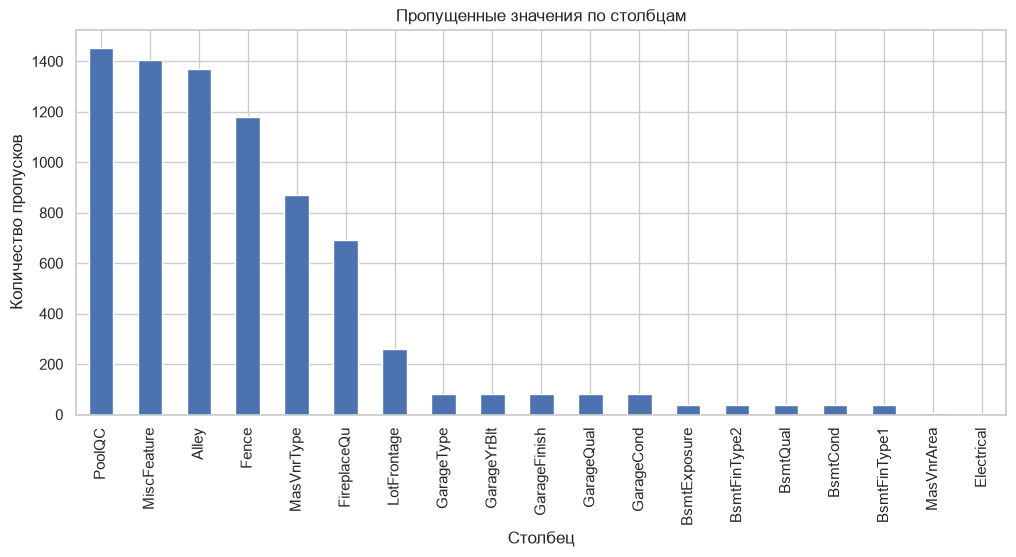

In [9]:
# Количество пропусков в столбцах, где они обнаружены
plt.figure(figsize=(12, 5))
missing_table["Пропуски"].sort_values(ascending=False).plot(kind="bar")
plt.xlabel("Столбец")
plt.ylabel("Количество пропусков")
plt.title("Пропущенные значения по столбцам")
plt.xticks(rotation=90)
plt.show()

### 5.7. Обработка выбросов

Для обнаружения потенциальных выбросов используется ***межквартильный размах (IQR)***. 

Выбросы **не следует автоматически удалять**: сначала необходимо проверить, являются ли они ошибками или реальными дорогими объектами.

In [10]:
q1 = train_df["GrLivArea"].quantile(0.25)
q3 = train_df["GrLivArea"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Количество объектов за пределами границ
outliers = train_df[
    (train_df["GrLivArea"] < lower_bound) |
    (train_df["GrLivArea"] > upper_bound)
]

print("Нижняя граница:", lower_bound)
print("Верхняя граница:", upper_bound)
print("Количество потенциальных выбросов:", len(outliers))

# Отдельная проверка большого дома с относительно низкой стоимостью
unusual_houses = train_df[
    (train_df["GrLivArea"] > 4000) &
    (train_df["SalePrice"] < 300000)
]

display(unusual_houses[["Id", "GrLivArea", "SalePrice"]])

Нижняя граница: 158.625
Верхняя граница: 2747.625
Количество потенциальных выбросов: 31


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


### Вывод 
Потенциальные выбросы не удаляются автоматически. Сначала проверяется их правдоподобие. Если значения соответствуют реальным объектам, их сохранение помогает модели учитывать широкий диапазон недвижимости.

### 5.8. Feature Engineering

Для улучшения качества прогнозирования создаются дополнительные признаки, описывающие площадь, возраст и оснащенность дома.

In [11]:
def create_features(df):
    # Создание копии, чтобы не изменять исходную таблицу
    df = df.copy()

    # Общая площадь жилых этажей и подвала
    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0)
        + df["1stFlrSF"].fillna(0)
        + df["2ndFlrSF"].fillna(0)
    )

    # Суммирование полноценных и половинных ванных комнат
    df["TotalBath"] = (
        df["FullBath"].fillna(0)
        + 0.5 * df["HalfBath"].fillna(0)
        + df["BsmtFullBath"].fillna(0)
        + 0.5 * df["BsmtHalfBath"].fillna(0)
    )

    # Суммирование площади крылец и веранд
    porch_cols = [
        "OpenPorchSF", "EnclosedPorch",
        "3SsnPorch", "ScreenPorch", "WoodDeckSF"
    ]
    df["TotalPorch"] = df[porch_cols].fillna(0).sum(axis=1)

    # Рассчёт возраста дома и времени после реконструкции
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

    # Создание признаков наличия дополнительных удобств
    df["HasPool"] = (df["PoolArea"].fillna(0) > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"].fillna(0) > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"].fillna(0) > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"].fillna(0) > 0).astype(int)

    # Добавление взаимодействия качества и площади
    df["OverallQual_TotalSF"] = df["OverallQual"] * df["TotalSF"]

    return df

# Применение к train и test
train_df = create_features(train_df)
test_df = create_features(test_df)

display(train_df[[
    "TotalSF", "TotalBath", "TotalPorch",
    "HouseAge", "RemodAge", "HasGarage"
]].head())

,TotalSF,TotalBath,TotalPorch,HouseAge,RemodAge,HasGarage
0,2566,3.5,61,5,5,1
1,2524,2.5,298,31,31,1
2,2706,3.5,42,7,6,1
3,2473,2.0,307,91,36,1
4,3343,3.5,276,8,8,1


### 5.9. Обработка пропусков и кодирование категорий

Для категориальных признаков отсутствие значения выделяется в категорию **None**. 

Для числовых признаков пропуски заполняются медианой, рассчитанной только по обучающей выборке. 

Категориальные переменные кодируются методом ***One-Hot Encoding***. Порядковые характеристики при необходимости можно закодировать вручную с учётом их естественного порядка.

In [12]:
# Отделяение целевой переменной и исключение служебных столбцов
y = np.log1p(train_df["SalePrice"])
X = train_df.drop(columns=["Id", "SalePrice", "SalePrice_log"], errors="ignore")

# Объединение train и test для одинакового набора закодированных признаков
all_features = pd.concat([X, test_df.drop(columns=["Id"], errors="ignore")], axis=0)

# Заполнение категориальных пропусков и числовых пропусков
cat_cols = all_features.select_dtypes(include="object").columns
num_cols = all_features.select_dtypes(exclude="object").columns

all_features[cat_cols] = all_features[cat_cols].fillna("None")
for col in num_cols:
    all_features[col] = all_features[col].fillna(all_features[col].median())

# Преобразование категориальных столбцов в числовые
all_features = pd.get_dummies(all_features, columns=cat_cols, dtype=int)

# Возвращение строк обучающей и тестовой выборок
X = all_features.iloc[:len(train_df)].copy()
X_competition_test = all_features.iloc[len(train_df):].copy()

# Деление обучающих данных для оценки качества моделей
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

print("Обучающая выборка:", X_train_scaled.shape)
print("Проверочная выборка:", X_valid_scaled.shape)

Обучающая выборка: (1168, 320)
Проверочная выборка: (292, 320)


C:\Users\User\AppData\Local\Temp\ipykernel_2920\1747775738.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = all_features.select_dtypes(include="object").columns


### Итоговые признаки

После заполнения пропусков и one-hot-кодирования категориальных столбцов итоговый список **feature_cols** содержит все признаки в том порядке, в котором они подаются в модель. Это важно для корректного масштабирования и последующего инференса.

In [13]:
# Сохранение точного порядка всех признаков после one-hot-кодирования
feature_cols = list(X.columns)

# Вывод нескольких признаков для проверки порядка и размерности
print("Количество признаков после кодирования:", len(feature_cols))
display(pd.DataFrame({"feature": feature_cols}).head(20))

Количество признаков после кодирования: 320


,feature
0,MSSubClass
1,LotFrontage
2,LotArea
3,OverallQual
4,OverallCond
5,YearBuilt
6,YearRemodAdd
7,MasVnrArea
8,BsmtFinSF1
9,BsmtFinSF2


### Общий вывод по разделу 5

В ходе **EDA** исследованы структура данных, пропуски, распределение стоимости и связь площади с ценой. 

Логарифмирование **SalePrice** уменьшает влияние правой асимметрии; потенциальные выбросы проверяются, а не удаляются автоматически. 

Созданы дополнительные признаки площади, возраста дома и наличия удобств. 

Категориальные признаки кодируются **one-hot-кодированием**, а пропуски заполняются без использования целевой переменной.

## 6. Построение и обучение моделей

### 6.1. Рассматриваемые модели

Для сравнения используются четыре модели: ***Linear Regression, Ridge, Lasso и ElasticNet***.

**Linear Regression** служит базовой моделью. **Ridge** ограничивает величину коэффициентов, **Lasso** может исключать часть признаков, а **ElasticNet** сочетает два вида регуляризации.

Модели обучаются на одинаковом разбиении данных. Для оценки времени используется модуль **time**.

In [14]:
# Создание  моделей с начальными параметрами
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.0005, max_iter=10000, random_state=42),
    "ElasticNet": ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
}

trained_models = {}
training_times = {}

# Обучение каждой модели и сохранение времени обучения
for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    training_times[name] = time.time() - start
    trained_models[name] = model

    print(name, "- время обучения:", round(training_times[name], 3), "сек.")

Linear Regression - время обучения: 0.212 сек.
Ridge - время обучения: 0.012 сек.
Lasso - время обучения: 0.218 сек.
ElasticNet - время обучения: 0.19 сек.


### 6.2. Подбор параметров Ridge и Lasso

Для подбора параметров применяется **кросс-валидация**. Она помогает выбрать параметр регуляризации на основе нескольких разбиений обучающей выборки.

In [15]:
# Использование одинаковых разбиений для сравнения вариантов параметров
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Подбор параметров alpha для Ridge
ridge_grid = GridSearchCV(
    Ridge(),
    {"alpha": [0.1, 1.0, 10.0, 100.0]},
    scoring="neg_root_mean_squared_error",
    cv=cv
)

start = time.time()
ridge_grid.fit(X_train_scaled, y_train)
training_times["Ridge GridSearchCV"] = time.time() - start
trained_models["Ridge"] = ridge_grid.best_estimator_

print("Лучший alpha для Ridge:", ridge_grid.best_params_)

# Подбор параметров alpha для Lasso
lasso_grid = GridSearchCV(
    Lasso(max_iter=20000, random_state=42),
    {"alpha": [0.0001, 0.0005, 0.001, 0.005]},
    scoring="neg_root_mean_squared_error",
    cv=cv
)

start = time.time()
lasso_grid.fit(X_train_scaled, y_train)
training_times["Lasso GridSearchCV"] = time.time() - start
trained_models["Lasso"] = lasso_grid.best_estimator_

print("Лучший alpha для Lasso:", lasso_grid.best_params_)

Лучший alpha для Ridge: {'alpha': 100.0}
Лучший alpha для Lasso: {'alpha': 0.005}


### Общий вывод по разделу 6

Сравниваются четыре обязательные модели: ***Linear Regression, Ridge, Lasso и ElasticNet***. Для всех используются одинаковые обучающие/проверочные объекты и одинаковое масштабирование. 

Параметры регуляризации **Ridge и Lasso** подбираются с помощью ***5-fold кросс-валидации***. 

Время обучения и лучшие параметры фиксируются для последующего сравнения.

## 7. Оценка качества

Оценка выполняется на проверочной выборке, которая не использовалась при обучении моделей. Сначала рассчитываются ***RMSE, MAE и $R^2$*** на логарифмированной шкале. Затем **RMSE** переводится в исходную шкалу цены для более понятной интерпретации.

### 7.1. Прогнозирование и расчёт метрик

In [16]:
results = {}
predictions = {}

# Рассчёт метрик для каждой модели
for name, model in trained_models.items():
    pred_log = model.predict(X_valid_scaled)
    predictions[name] = pred_log

    rmse_log = np.sqrt(mean_squared_error(y_valid, pred_log))
    mae_log = mean_absolute_error(y_valid, pred_log)
    r2 = r2_score(y_valid, pred_log)

    # Возвращение логарифмированных цен к исходным значениям
    pred_price = np.expm1(pred_log)
    true_price = np.expm1(y_valid)

    rmse_price = np.sqrt(mean_squared_error(true_price, pred_price))
    mae_price = mean_absolute_error(true_price, pred_price)

    results[name] = {
        "RMSE_log": rmse_log,
        "MAE_log": mae_log,
        "R2_log": r2,
        "RMSE_price": rmse_price,
        "MAE_price": mae_price,
        "Время_сек": training_times.get(name, np.nan)
    }

# Вывод сводной таблицы по всем моделям
results_df = pd.DataFrame(results).T
display(results_df.sort_values("RMSE_log"))

,RMSE_log,MAE_log,R2_log,RMSE_price,MAE_price,Время_сек
ElasticNet,0.122795,0.085340,0.919197,22042.080432,14428.118424,0.189884
Lasso,0.123825,0.084161,0.917837,22345.247714,14273.544791,0.218323
Ridge,0.126016,0.087928,0.914902,22620.202748,14952.235857,0.012298
Linear Regression,0.152671,0.093903,0.875096,24572.641778,15618.506800,0.211547


### 7.2. Сравнение RMSE

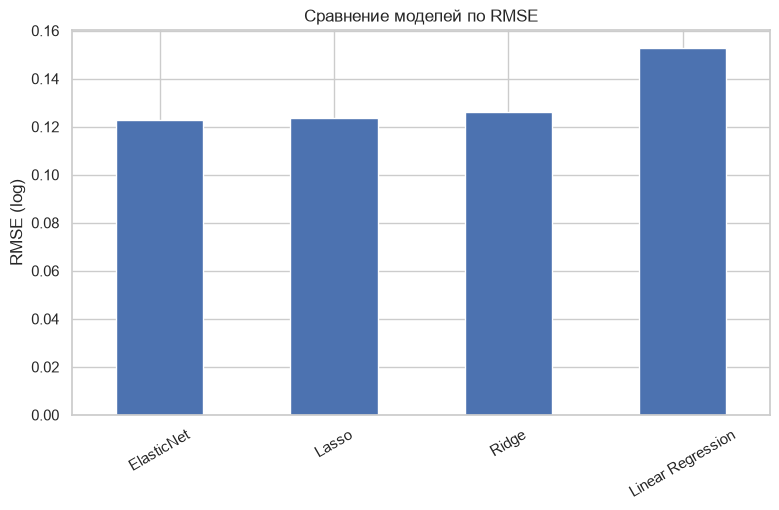

In [17]:
# Сравнение модели по RMSE на логарифмированной шкале
results_df["RMSE_log"].sort_values().plot(kind="bar", figsize=(9, 5))
plt.ylabel("RMSE (log)")
plt.title("Сравнение моделей по RMSE")
plt.xticks(rotation=30)
plt.show()

### 7.3. Фактические и спрогнозированные цены

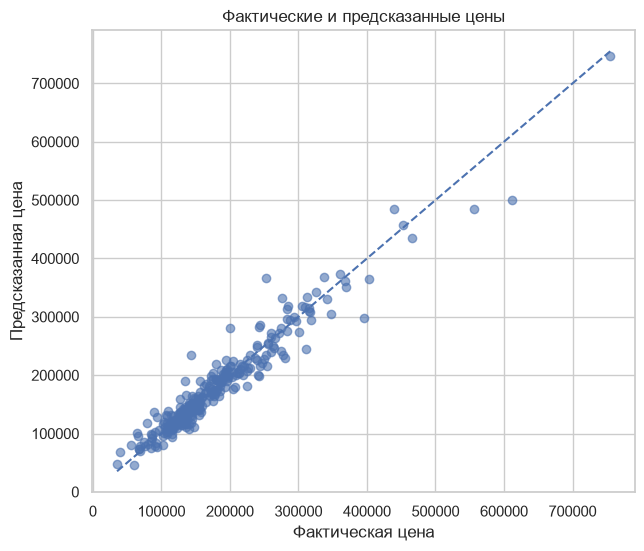

Лучшая модель по RMSE: ElasticNet


In [18]:
# График фактических и предсказанных цен для лучшей модели
best_model_name = results_df["RMSE_log"].idxmin()
best_model = trained_models[best_model_name]

best_pred_price = np.expm1(best_model.predict(X_valid_scaled))
true_price = np.expm1(y_valid)

plt.figure(figsize=(7, 6))
plt.scatter(true_price, best_pred_price, alpha=0.6)

# Линия показывает идеальное совпадение прогноза и факта
low = min(true_price.min(), best_pred_price.min())
high = max(true_price.max(), best_pred_price.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Фактическая цена")
plt.ylabel("Предсказанная цена")
plt.title("Фактические и предсказанные цены")
plt.show()

print("Лучшая модель по RMSE:", best_model_name)

### 7.4. Анализ остатков

***Остаток*** - это разница между фактической и спрогноированной стоимостью. 

**Анализ остатков** позволяет выявить систематические ошибки модели.

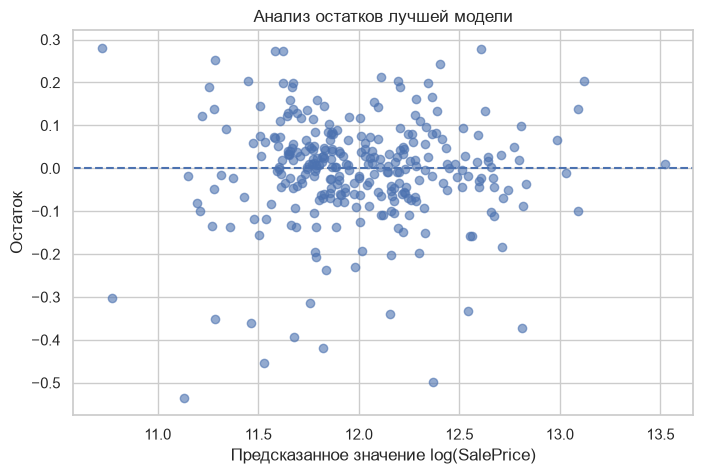

Средний остаток: -0.0057673323105025725
Стандартное отклонение остатков: 0.12287020560254804


In [19]:
# Рассчёт остатков для лучшей модели на логарифмической шкале
best_pred_log = best_model.predict(X_valid_scaled)
residuals = y_valid - best_pred_log

plt.figure(figsize=(8, 5))
plt.scatter(best_pred_log, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Предсказанное значение log(SalePrice)")
plt.ylabel("Остаток")
plt.title("Анализ остатков лучшей модели")
plt.show()

print("Средний остаток:", residuals.mean())
print("Стандартное отклонение остатков:", residuals.std())

### Общий вывод по разделу 7

Лучшая модель определяется по минимальному **RMSE_log** на проверочной выборке; итоговое название и метрики выводятся из рассчитанной таблицы, а не задаются заранее. 

**RMSE и MAE** на логарифмической шкале измеряют ошибку логарифма цены, тогда как **RMSE** в долларах показывает масштаб ошибки в исходных единицах. 

Графики фактических и прогнозируемых цен и остатков помогают оценить систематические отклонения.

## 8. Интерпретация результатов

### 8.1. Интерпретация

**Коэффициенты линейных моделей** показывают **направление связи** признаков с прогнозированием при фиксированных остальных признаках. 

Поскольку признаки **масштабированы**, коэффициенты относятся к **стандартизированным** значениям признаков. 

Для категориальных признаков после ***One-Hot Encoding*** коэффициент отражает влияние соответствующего индикатора относительно базовой комбинации признаков.

,Признак,Коэффициент,Абсолютный коэффициент
36,TotalSF,0.100102,0.100102
137,RoofMatl_ClyTile,-0.074843,0.074843
3,OverallQual,0.071991,0.071991
15,GrLivArea,0.067085,0.067085
39,HouseAge,-0.044152,0.044152
4,OverallCond,0.039177,0.039177
45,OverallQual_TotalSF,-0.038234,0.038234
114,Condition2_PosN,-0.034534,0.034534
26,GarageArea,0.028730,0.028730
82,Neighborhood_Crawfor,0.024215,0.024215


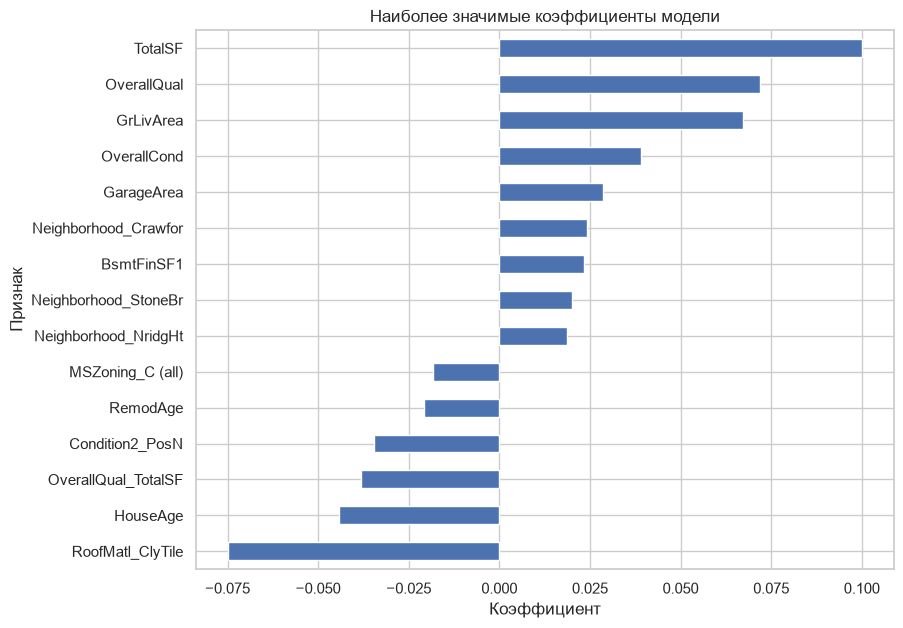

In [20]:
# Получение коэффициентов лучшей модели, если она является линейной
if hasattr(best_model, "coef_"):
    coef_table = pd.DataFrame({
        "Признак": X.columns,
        "Коэффициент": best_model.coef_
    })

    # Выбор признаков с наибольшими по модулю коэффициентами
    coef_table["Абсолютный коэффициент"] = coef_table["Коэффициент"].abs()
    coef_table = coef_table.sort_values(
        "Абсолютный коэффициент", ascending=False
    )

    display(coef_table.head(15))

    coef_table.head(15).sort_values("Коэффициент").plot(
        x="Признак", y="Коэффициент",
        kind="barh", figsize=(9, 7), legend=False
    )
    plt.title("Наиболее значимые коэффициенты модели")
    plt.xlabel("Коэффициент")
    plt.show()
else:
    print("Для выбранной модели прямые коэффициенты недоступны.")

### 8.2. Коэффициенты Ridge

Коэффициенты построены для стандартизованных признаков. Положительный коэффициент связан с увеличением прогнозируемого **log1p(SalePrice)**, отрицательный - с уменьшением при прочих равных условиях. 

Величина зависит от масштабирования и регуляризации.

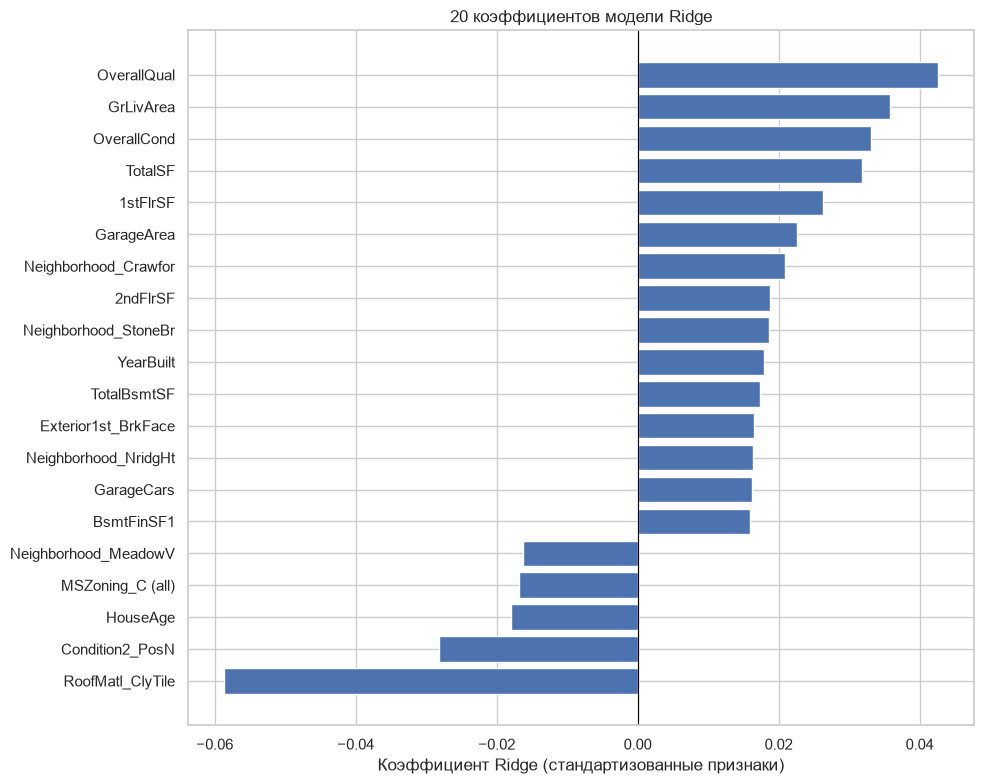

,Feature,Coefficient
3,OverallQual,0.042642
15,GrLivArea,0.035855
4,OverallCond,0.033165
36,TotalSF,0.031790
12,1stFlrSF,0.026341
26,GarageArea,0.022533
82,Neighborhood_Crawfor,0.020936
13,2ndFlrSF,0.018783
98,Neighborhood_StoneBr,0.018643
5,YearBuilt,0.017869


In [21]:
# Коэффициенты Ridge с именами признаков в исходном порядке
ridge_model = trained_models["Ridge"]
ridge_coefficients = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": ridge_model.coef_
}).sort_values("Coefficient", ascending=False)

# Для графика берём 20 коэффициентов с наибольшим абсолютным значением
ridge_top20 = ridge_coefficients.reindex(
    ridge_coefficients["Coefficient"].abs().sort_values(ascending=False).head(20).index
).sort_values("Coefficient")

plt.figure(figsize=(10, 8))
plt.barh(ridge_top20["Feature"], ridge_top20["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент Ridge (стандартизованные признаки)")
plt.title("20 коэффициентов модели Ridge")
plt.tight_layout()
plt.show()

display(ridge_top20.sort_values("Coefficient", ascending=False))

### 8.3. Отбор признаков через Lasso

**Lasso** может занулять коэффициенты, тем самым выполняя встроенный отбор признаков. 

Число нулевых и ненулевых коэффициентов выводится из обученной модели; ненулевой коэффициент не обязательно означает причинное влияние.

In [22]:
# Количество нулевых коэффициентов Lasso и число оставшихся признаков
lasso_model = trained_models["Lasso"]
lasso_coef = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lasso_model.coef_
})
n_zero = int((lasso_model.coef_ == 0).sum())
n_total = len(lasso_model.coef_)
print(f"Lasso обнулил: {n_zero} из {n_total} признаков.")
print(f"Ненулевых коэффициентов осталось: {n_total - n_zero}.")

# Вывод наиболее положительных и отрицательных ненулевых коэффициентов
non_zero = lasso_coef[lasso_coef["Coefficient"] != 0].copy()
display(non_zero.reindex(non_zero["Coefficient"].abs().sort_values(ascending=False).head(15).index))

Lasso обнулил: 227 из 320 признаков.
Ненулевых коэффициентов осталось: 93.


,Feature,Coefficient
36,TotalSF,0.079153
3,OverallQual,0.078606
15,GrLivArea,0.068663
137,RoofMatl_ClyTile,-0.068277
39,HouseAge,-0.039004
4,OverallCond,0.034057
114,Condition2_PosN,-0.029839
26,GarageArea,0.023637
37,TotalBath,0.023052
40,RemodAge,-0.021388


### Бизнес-интерпретация

Знаки коэффициентов показывают направление связи признака с логарифмом цены при фиксированных остальных признаках. Для стандартизованных признаков коэффициенты нельзя напрямую трактовать как изменение цены на один исходный пункт. Категориальные признаки после one-hot-кодирования сравниваются с базовыми категориями.

## Вывод по разделу
У Ridge наиболее влиятельными считаются признаки с наибольшими коэффициентами по модулю; знак коэффициента показывает направление связи в рамках модели. Lasso оставляет **n_selected** признаков с ненулевыми коэффициентами из **n_total**, то есть обнуляет **n_zero**. Эти числа позволяют количественно оценить степень отбора признаков, но коэффициенты стандартизированной модели нельзя напрямую трактовать как изменение цены в долларах.

## 9. Функция прогнозироания

Функция ***predict_price()*** принимает словарь характеристик нового дома, модель, обученный **StandardScaler** и список признаков в правильном порядке. 

Для признаков, отсутствующих во входном словаре, используются нулевые значения; для категориальных признаков это соответствует нулевым **one-hot-индикаторам**. Для практического использования желательно передавать полный набор доступных характеристик и те же правила **Feature Engineering**, что применялись при обучении.

Модель прогнозирует ***log1p(SalePrice)***, поэтому результат преобразуется обратно в доллары с помощью **expm1()**.

In [23]:
def predict_price(house_data, model, scaler, feature_cols):
    
    # Создание DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # Заполнение отсутствующих признаки нулями
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # Остаются только нужные признаки в правильном порядке
    X_new = X_new[feature_cols]

    X_new_scaled = scaler.transform(X_new)

    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_new_scaled)[0]

    # Возврат в доллары
    y_pred_real = np.expm1(y_pred_log)

    return float(y_pred_real)

# Демонстрация на пяти домах с разными профилями
house_examples = [
    {
        "Профиль": "Дорогой",
        "OverallQual": 9, "GrLivArea": 2800, "TotalSF": 4600,
        "YearBuilt": 2015, "GarageCars": 3, "TotalBath": 3.5,
    },
    {
        "Профиль": "Средний",
        "OverallQual": 6, "GrLivArea": 1500, "TotalSF": 2500,
        "YearBuilt": 2000, "GarageCars": 2, "TotalBath": 2.0,
    },
    {
        "Профиль": "Дешёвый",
        "OverallQual": 4, "GrLivArea": 900, "TotalSF": 1500,
        "YearBuilt": 1950, "GarageCars": 1, "TotalBath": 1.0,
    },
    {
        "Профиль": "Элитный",
        "OverallQual": 10, "GrLivArea": 4000, "TotalSF": 6000,
        "YearBuilt": 2018, "GarageCars": 4, "TotalBath": 4.0,
    },
    {
        "Профиль": "Средний",
        "OverallQual": 5, "GrLivArea": 1200, "TotalSF": 1800,
        "YearBuilt": 1985, "GarageCars": 1, "TotalBath": 1.5,
    },
]

# Для каждого дома вывод исходных характеристик и прогноз каждой модели
prediction_rows = []
for i, example in enumerate(house_examples, start=1):
    house_data = {key: value for key, value in example.items() if key != "Профиль"}
    print(f"Дом {i} - {example['Профиль']}")
    display(pd.DataFrame([house_data], index=[f"Дом {i}"]))

    row = {"Дом": i, "Профиль": example["Профиль"]}
    for model_name in ["Linear Regression", "Ridge", "Lasso", "ElasticNet"]:
        if model_name in trained_models:
            row[f"{model_name}, $"] = predict_price(
                house_data, trained_models[model_name], scaler, feature_cols
            )
    prediction_rows.append(row)

predictions_examples_df = pd.DataFrame(prediction_rows)
print("\nСравнение прогнозов всех моделей (цены в долларах США):")
display(predictions_examples_df.style.format({
    col: "${:,.0f}" for col in predictions_examples_df.columns if col.endswith("$")
}))


Дом 1 - Дорогой


,OverallQual,GrLivArea,TotalSF,YearBuilt,GarageCars,TotalBath
Дом 1,9,2800,4600,2015,3,3.5


C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Дом 2 - Средний


C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0


...

Дом 5 - Средний


,OverallQual,GrLivArea,TotalSF,YearBuilt,GarageCars,TotalBath
Дом 5,5,1200,1800,1985,1,1.5


C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 


Сравнение прогнозов всех моделей (цены в долларах США):


,Дом,Профиль,"Linear Regression, $","Ridge, $","Lasso, $","ElasticNet, $"
0,1,Дорогой,"$459,658","$839,078","$215,678","$182,678"
1,2,Средний,"$225,168","$610,080","$116,635","$97,943"
2,3,Дешёвый,"$144,966","$494,844","$82,628","$68,706"
3,4,Элитный,"$703,882","$1,024,026","$318,411","$272,358"
4,5,Средний,"$178,121","$542,434","$95,094","$79,863"


### Вывод по разделу 9

Функция возвращает числовую оценку цены в долларах и использует тот же scaler и порядок признаков, что и обучение. 

Пять примеров позволяют сравнить реакцию моделей на дома разного качества и площади. 

## 10. Сохранение модели и вспомогательных объектов

Модели сохраняются в папку **models/** в формате **.pkl**. Дополнительно сохраняются scaler, упорядоченный список признаков и метрики. Файлы создаются относительно каталога ноутбука.

In [24]:
# Создание каталога для артефактов обучения
os.makedirs("models", exist_ok=True)

# Сохранение каждой из четырёх обученных моделей под отдельным именем
model_filenames = {
    "Linear Regression": "lr_model.pkl",
    "Ridge": "ridge_model.pkl",
    "Lasso": "lasso_model.pkl",
    "ElasticNet": "enet_model.pkl",
}
for model_name, filename in model_filenames.items():
    joblib.dump(trained_models[model_name], os.path.join("models", filename))

# Сохранение модели с минимальным RMSE на проверочной выборке и общий scaler
joblib.dump(best_model, "models/best_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")

# Сохранение порядока признаков и метрики в JSON-формате
with open("models/feature_cols.json", "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

metrics_to_save = {
    name: {key: float(value) for key, value in row.items() if pd.notna(value)}
    for name, row in results_df.to_dict(orient="index").items()
}
metrics_to_save["best_model"] = best_model_name
with open("models/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_to_save, f, ensure_ascii=False, indent=2)

print("Сохранены модели, scaler, feature_cols.json и metrics.json.")
print("Лучшая модель по RMSE_log:", best_model_name)

Сохранены модели, scaler, feature_cols.json и metrics.json.
Лучшая модель по RMSE_log: ElasticNet


## 11. Загрузка модели из репозитория 

In [25]:
# Адрес репозитория и ветка, в которой лежат модели
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "ZhdanovaAnna/ml-course-zhdanova/main/"
    "module-2-house-prices"
)

def download_bytes(url):
    # Проверка HTTP-статуса
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return response.content

# Загрузка выполняется после публикации файлов в GitHub
try:
    loaded_model = joblib.load(BytesIO(download_bytes(f"{BASE_URL}/models/best_model.pkl")))
    loaded_scaler = joblib.load(BytesIO(download_bytes(f"{BASE_URL}/models/scaler.pkl")))
    feature_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)
    feature_response.raise_for_status()
    loaded_feature_cols = feature_response.json()

    # Проверка, что порядок признаков соответствует локальной версии
    assert loaded_feature_cols == feature_cols, "Порядок признаков в репозитории отличается."
    print("Модель, scaler и список признаков успешно загружены.")

    # Проверка трех профилей: загруженная и локальная модели должны совпасть
    for i, house in enumerate(house_examples[:3], start=1):
        local_pred = predict_price(house, best_model, scaler, feature_cols)
        remote_pred = predict_price(house, loaded_model, loaded_scaler, loaded_feature_cols)
        print(f"Дом {i}: локальный прогноз = ${local_pred:,.0f}; "
              f"загруженный = ${remote_pred:,.0f}; "
              f"Совпадение = {np.isclose(local_pred, remote_pred, rtol=1e-8)}")
except requests.RequestException as exc:
    print("Не удалось загрузить. Проверьте BASE_URL и наличие файлов в GitHub.")
    print("Подробности:", exc)

Модель, scaler и список признаков успешно загружены.


C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Дом 1: локальный прогноз = $182,678; загруженный = $182,678; Совпадение = True
Дом 2: локальный прогноз = $97,943; загруженный = $97,943; Совпадение = True


C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_2920\4108037190.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Дом 3: локальный прогноз = $68,706; загруженный = $68,706; Совпадение = True


### Вывод по разделу 11

После публикации артефактов в публичном репозитории этот раздел загружает модель и scaler без переобучения, сверяет порядок признаков и сравнивает прогнозы для трёх домов. 

Успешная проверка подтверждается совпадением локальных и загруженных прогнозов. 

## 12. Выводы

### Что получилось

1) Проведён EDA: изучены размеры и типы данных, пропуски, распределение цены, корреляции, связь площади с ценой и потенциальные выбросы.

2) Созданы дополнительные признаки и выполнено кодирование категориальных характеристик.

3) Сравнены ***Linear Regression, Ridge, Lasso и ElasticNet***; рассчитаны ***RMSE, MAE, R²***, ошибка в долларах и время обучения.

4) Лучшая модель определяется по фактическому минимальному **RMSE_log**.

5) Проведена интерпретация коэффициентов и создана функция предсказания для новых объектов.

### Трудности и ограничения

1) В датасете много пропусков, причём в ряде категориальных полей пропуск означает отсутствие соответствующего объекта или удобства, а не неизвестное значение.

2) **SalePrice** имеет правую асимметрию; для обучения использована шкала **log1p(SalePrice)**.

3) Коррелирующие признаки (например, разные показатели площади и гаража) могут приводить к нестабильности коэффициентов обычной линейной регрессии.

4) Демонстрационные профили для **predict_price()** содержат не все исходные характеристики, поэтому пропущенные признаки заполняются нулями. 

5) Проверка загрузки из GitHub зависит от публикации файлов и корректного **BASE_URL**.

### Возможные улучшения

1) Применить Target Encoding для **Neighborhood** внутри кросс-валидации.

2) Сравнить линейные модели с ***XGBoost, LightGBM или HistGradientBoostingRegressor***.

3) Использовать Optuna для более широкого подбора гиперпараметров.

4) Проверить ***RFE или SelectFromModel*** для отбора признаков.

5) Построить ***Stacking*** из Ridge, Lasso и градиентного бустинга.

6) Использовать **Pipeline и ColumnTransformer**, чтобы избежать утечки данных при заполнении пропусков и кодировании.

7) Оценить устойчивость качества на повторной кросс-валидации и отдельно проанализировать ошибки для разных ценовых сегментов.

## 13. Источники

1) Kaggle. *House Prices - Advanced Regression Techniques*. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

2) Scikit-learn. *Linear Models*. https://scikit-learn.org/stable/modules/linear_model.html

3) Scikit-learn. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

4) Scikit-learn. *Preprocessing data*. https://scikit-learn.org/stable/modules/preprocessing.html

5) pandas. *User Guide*. https://pandas.pydata.org/docs/user_guide/

## 14. Приложение

Ниже приведён полный код ячеек ноутбука в формате Jupytext (# %%). Он включает импорты, загрузку данных, анализ, обучение, оценку, предсказание и сохранение артефактов. 

Перед запуском убедитесь, что **data/train.csv и data/test.csv** доступны по относительным путям.

### requirements.txt

```text
numpy==1.24.0
pandas==2.0.0
matplotlib==3.7.0
seaborn==0.12.0
scikit-learn==1.3.0
joblib==1.3.0
requests==2.31.0
```

### Полный код

```python
# %%
# Импорт библиотек 
import os
import time
import json
import joblib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# %%
# Загрузка данных
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# %%
# Первичный осмотр
print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)

display(train_df.head())

train_df.info()

display(train_df.describe())

print("Асимметрия:", train_df["SalePrice"].skew())
print("Эксцесс:", train_df["SalePrice"].kurtosis())

# %%
# Подготовка данных и EDA
missing_count = train_df.isnull().sum()

missing_percent = missing_count / len(train_df) * 100

missing_table = pd.DataFrame({
    "Пропуски": missing_count,
    "Пропуски, %": missing_percent
})

missing_table = missing_table[missing_table["Пропуски"] > 0]

missing_table = missing_table.sort_values("Пропуски", ascending=False)

display(missing_table)

if not missing_table.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing_table["Пропуски"].head(25),
        y=missing_table.index[:25]
    )
    plt.title("Количество пропущенных значений по столбцам")
    plt.xlabel("Количество пропусков")
    plt.ylabel("Признак")
    plt.tight_layout()
    plt.show()

# %%
train_df["SalePrice_log"] = np.log1p(train_df["SalePrice"])

print("Асимметрия SalePrice:", train_df["SalePrice"].skew())
print("Асимметрия SalePrice_log:", train_df["SalePrice_log"].skew())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Распределение SalePrice")
axes[0].set_xlabel("Цена продажи, $")

sns.histplot(train_df["SalePrice_log"], kde=True, ax=axes[1])
axes[1].set_title("Распределение log1p(SalePrice)")
axes[1].set_xlabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

# %%
# Корреляционная матрица
numeric_data = train_df.select_dtypes(include=np.number)

corr_matrix = numeric_data.corr()

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 9))
sns.heatmap(
    numeric_data[top_corr.index].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Корреляционная матрица наиболее связанных числовых признаков")
plt.tight_layout()
plt.show()

# %%
# Диаграмма рассеяния площади и цены продажи
plt.figure(figsize=(9, 6))
sns.scatterplot(data=train_df, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.title("Зависимость цены от жилой площади")
plt.xlabel("Жилая площадь, кв. футы")
plt.ylabel("Цена продажи, $")
plt.tight_layout()
plt.show()

# %%
# Сравнение распределения жилой площади для разных оценок качества
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df, x="OverallQual", y="GrLivArea")
plt.xlabel("Общая оценка качества")
plt.ylabel("Жилая площадь")
plt.title("Жилая площадь в зависимости от качества дома")
plt.show()

# %%
# Количество пропусков в столбцах, где они обнаружены
plt.figure(figsize=(12, 5))
missing_table["Пропуски"].sort_values(ascending=False).plot(kind="bar")
plt.xlabel("Столбец")
plt.ylabel("Количество пропусков")
plt.title("Пропущенные значения по столбцам")
plt.xticks(rotation=90)
plt.show()

# %%
# Обработка выбросов
q1 = train_df["GrLivArea"].quantile(0.25)
q3 = train_df["GrLivArea"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = train_df[
    (train_df["GrLivArea"] < lower_bound) |
    (train_df["GrLivArea"] > upper_bound)
]

print("Нижняя граница:", lower_bound)
print("Верхняя граница:", upper_bound)
print("Количество потенциальных выбросов:", len(outliers))

unusual_houses = train_df[
    (train_df["GrLivArea"] > 4000) &
    (train_df["SalePrice"] < 300000)
]

display(unusual_houses[["Id", "GrLivArea", "SalePrice"]])

# %%
# Feature Engineering
def create_features(df):
    df = df.copy()

    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0)
        + df["1stFlrSF"].fillna(0)
        + df["2ndFlrSF"].fillna(0)
    )

    df["TotalBath"] = (
        df["FullBath"].fillna(0)
        + 0.5 * df["HalfBath"].fillna(0)
        + df["BsmtFullBath"].fillna(0)
        + 0.5 * df["BsmtHalfBath"].fillna(0)
    )

    porch_cols = [
        "OpenPorchSF", "EnclosedPorch",
        "3SsnPorch", "ScreenPorch", "WoodDeckSF"
    ]
    df["TotalPorch"] = df[porch_cols].fillna(0).sum(axis=1)

    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

    df["HasPool"] = (df["PoolArea"].fillna(0) > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"].fillna(0) > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"].fillna(0) > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"].fillna(0) > 0).astype(int)

    df["OverallQual_TotalSF"] = df["OverallQual"] * df["TotalSF"]

    return df

train_df = create_features(train_df)
test_df = create_features(test_df)

display(train_df[[
    "TotalSF", "TotalBath", "TotalPorch",
    "HouseAge", "RemodAge", "HasGarage"
]].head())

# %%
# Обработка пропусков и кодирование категорий
y = np.log1p(train_df["SalePrice"])
X = train_df.drop(columns=["Id", "SalePrice", "SalePrice_log"], errors="ignore")

all_features = pd.concat([X, test_df.drop(columns=["Id"], errors="ignore")], axis=0)

cat_cols = all_features.select_dtypes(include="object").columns
num_cols = all_features.select_dtypes(exclude="object").columns

all_features[cat_cols] = all_features[cat_cols].fillna("None")
for col in num_cols:
    all_features[col] = all_features[col].fillna(all_features[col].median())

all_features = pd.get_dummies(all_features, columns=cat_cols, dtype=int)

X = all_features.iloc[:len(train_df)].copy()
X_competition_test = all_features.iloc[len(train_df):].copy()

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

print("Обучающая выборка:", X_train_scaled.shape)
print("Проверочная выборка:", X_valid_scaled.shape)

# %%
# Итоговые признаки
feature_cols = list(X.columns)
print("Количество признаков после кодирования:", len(feature_cols))
display(pd.DataFrame({"feature": feature_cols}).head(20))

# %%
# Построение и обучение моделей
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.0005, max_iter=10000, random_state=42),
    "ElasticNet": ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
}

trained_models = {}
training_times = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    training_times[name] = time.time() - start
    trained_models[name] = model

    print(name, "- время обучения:", round(training_times[name], 3), "сек.")

# %%
# Подбор параметров Ridge и Lasso
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_grid = GridSearchCV(
    Ridge(),
    {"alpha": [0.1, 1.0, 10.0, 100.0]},
    scoring="neg_root_mean_squared_error",
    cv=cv
)

start = time.time()
ridge_grid.fit(X_train_scaled, y_train)
training_times["Ridge GridSearchCV"] = time.time() - start
trained_models["Ridge"] = ridge_grid.best_estimator_

print("Лучший alpha для Ridge:", ridge_grid.best_params_)

lasso_grid = GridSearchCV(
    Lasso(max_iter=20000, random_state=42),
    {"alpha": [0.0001, 0.0005, 0.001, 0.005]},
    scoring="neg_root_mean_squared_error",
    cv=cv
)

start = time.time()
lasso_grid.fit(X_train_scaled, y_train)
training_times["Lasso GridSearchCV"] = time.time() - start
trained_models["Lasso"] = lasso_grid.best_estimator_

print("Лучший alpha для Lasso:", lasso_grid.best_params_)

# %%
# Прогнозирование и расчёт метрик
results = {}
predictions = {}

for name, model in trained_models.items():
    pred_log = model.predict(X_valid_scaled)
    predictions[name] = pred_log

    rmse_log = np.sqrt(mean_squared_error(y_valid, pred_log))
    mae_log = mean_absolute_error(y_valid, pred_log)
    r2 = r2_score(y_valid, pred_log)

    pred_price = np.expm1(pred_log)
    true_price = np.expm1(y_valid)

    rmse_price = np.sqrt(mean_squared_error(true_price, pred_price))
    mae_price = mean_absolute_error(true_price, pred_price)

    results[name] = {
        "RMSE_log": rmse_log,
        "MAE_log": mae_log,
        "R2_log": r2,
        "RMSE_price": rmse_price,
        "MAE_price": mae_price,
        "Время_сек": training_times.get(name, np.nan)
    }

results_df = pd.DataFrame(results).T
display(results_df.sort_values("RMSE_log"))

# %%
# Сравнивнение модели по RMSE на логарифмированной шкале
results_df["RMSE_log"].sort_values().plot(kind="bar", figsize=(9, 5))
plt.ylabel("RMSE (log)")
plt.title("Сравнение моделей по RMSE")
plt.xticks(rotation=30)
plt.show()

# %%
# График фактических и предсказанных цен для лучшей модели
best_model_name = results_df["RMSE_log"].idxmin()
best_model = trained_models[best_model_name]

best_pred_price = np.expm1(best_model.predict(X_valid_scaled))
true_price = np.expm1(y_valid)

plt.figure(figsize=(7, 6))
plt.scatter(true_price, best_pred_price, alpha=0.6)

low = min(true_price.min(), best_pred_price.min())
high = max(true_price.max(), best_pred_price.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Фактическая цена")
plt.ylabel("Предсказанная цена")
plt.title("Фактические и предсказанные цены")
plt.show()

print("Лучшая модель по RMSE:", best_model_name)

# %%
# Рассчёт остатков для лучшей модели на логарифмической шкале
best_pred_log = best_model.predict(X_valid_scaled)
residuals = y_valid - best_pred_log

plt.figure(figsize=(8, 5))
plt.scatter(best_pred_log, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Предсказанное значение log(SalePrice)")
plt.ylabel("Остаток")
plt.title("Анализ остатков лучшей модели")
plt.show()

print("Средний остаток:", residuals.mean())
print("Стандартное отклонение остатков:", residuals.std())

# %%
# Интерпретация результатов
if hasattr(best_model, "coef_"):
    coef_table = pd.DataFrame({
        "Признак": X.columns,
        "Коэффициент": best_model.coef_
    })

    coef_table["Абсолютный коэффициент"] = coef_table["Коэффициент"].abs()
    coef_table = coef_table.sort_values(
        "Абсолютный коэффициент", ascending=False
    )

    display(coef_table.head(15))

    coef_table.head(15).sort_values("Коэффициент").plot(
        x="Признак", y="Коэффициент",
        kind="barh", figsize=(9, 7), legend=False
    )
    plt.title("Наиболее значимые коэффициенты модели")
    plt.xlabel("Коэффициент")
    plt.show()
else:
    print("Для выбранной модели прямые коэффициенты недоступны.")

# %%
# Коэффициенты Ridge 
ridge_model = trained_models["Ridge"]
ridge_coefficients = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": ridge_model.coef_
}).sort_values("Coefficient", ascending=False)

ridge_top20 = ridge_coefficients.reindex(
    ridge_coefficients["Coefficient"].abs().sort_values(ascending=False).head(20).index
).sort_values("Coefficient")

plt.figure(figsize=(10, 8))
plt.barh(ridge_top20["Feature"], ridge_top20["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент Ridge (стандартизованные признаки)")
plt.title("ТОП-20 коэффициентов модели Ridge")
plt.tight_layout()
plt.show()

display(ridge_top20.sort_values("Coefficient", ascending=False))

# %%
# Отбор признаков через Lasso
lasso_model = trained_models["Lasso"]
lasso_coef = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lasso_model.coef_
})
n_zero = int((lasso_model.coef_ == 0).sum())
n_total = len(lasso_model.coef_)
print(f"Lasso обнулил: {n_zero} из {n_total} признаков.")
print(f"Ненулевых коэффициентов осталось: {n_total - n_zero}.")

non_zero = lasso_coef[lasso_coef["Coefficient"] != 0].copy()
display(non_zero.reindex(non_zero["Coefficient"].abs().sort_values(ascending=False).head(15).index))

# %%
# Функция прогнозироания
def predict_price(house_data, model, scaler, feature_cols):
    
    X_new = pd.DataFrame([house_data])

    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    X_new = X_new[feature_cols]

    X_new_scaled = scaler.transform(X_new)

    y_pred_log = model.predict(X_new_scaled)[0]

    y_pred_real = np.expm1(y_pred_log)

    return float(y_pred_real)

house_examples = [
    {
        "Профиль": "Дорогой",
        "OverallQual": 9, "GrLivArea": 2800, "TotalSF": 4600,
        "YearBuilt": 2015, "GarageCars": 3, "TotalBath": 3.5,
    },
    {
        "Профиль": "Средний",
        "OverallQual": 6, "GrLivArea": 1500, "TotalSF": 2500,
        "YearBuilt": 2000, "GarageCars": 2, "TotalBath": 2.0,
    },
    {
        "Профиль": "Дешёвый",
        "OverallQual": 4, "GrLivArea": 900, "TotalSF": 1500,
        "YearBuilt": 1950, "GarageCars": 1, "TotalBath": 1.0,
    },
    {
        "Профиль": "Элитный",
        "OverallQual": 10, "GrLivArea": 4000, "TotalSF": 6000,
        "YearBuilt": 2018, "GarageCars": 4, "TotalBath": 4.0,
    },
    {
        "Профиль": "Средний",
        "OverallQual": 5, "GrLivArea": 1200, "TotalSF": 1800,
        "YearBuilt": 1985, "GarageCars": 1, "TotalBath": 1.5,
    },
]

prediction_rows = []
for i, example in enumerate(house_examples, start=1):
    house_data = {key: value for key, value in example.items() if key != "Профиль"}
    print(f"Дом {i} - {example['Профиль']}")
    display(pd.DataFrame([house_data], index=[f"Дом {i}"]))

    row = {"Дом": i, "Профиль": example["Профиль"]}
    for model_name in ["Linear Regression", "Ridge", "Lasso", "ElasticNet"]:
        if model_name in trained_models:
            row[f"{model_name}, $"] = predict_price(
                house_data, trained_models[model_name], scaler, feature_cols
            )
    prediction_rows.append(row)

predictions_examples_df = pd.DataFrame(prediction_rows)
print("\nСравнение прогнозов всех моделей (цены в долларах США):")
display(predictions_examples_df.style.format({
    col: "${:,.0f}" for col in predictions_examples_df.columns if col.endswith("$")
}))

# %%
# Сохранение модели и вспомогательных объектов
os.makedirs("models", exist_ok=True)

model_filenames = {
    "Linear Regression": "lr_model.pkl",
    "Ridge": "ridge_model.pkl",
    "Lasso": "lasso_model.pkl",
    "ElasticNet": "enet_model.pkl",
}
for model_name, filename in model_filenames.items():
    joblib.dump(trained_models[model_name], os.path.join("models", filename))

joblib.dump(best_model, "models/best_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")

with open("models/feature_cols.json", "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

metrics_to_save = {
    name: {key: float(value) for key, value in row.items() if pd.notna(value)}
    for name, row in results_df.to_dict(orient="index").items()
}
metrics_to_save["best_model"] = best_model_name
with open("models/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_to_save, f, ensure_ascii=False, indent=2)

print("Сохранены модели, scaler, feature_cols.json и metrics.json.")
print("Лучшая модель по RMSE_log:", best_model_name)

# %%
# Загрузка модели из репозитория 
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "ZhdanovaAnna/ml-course-zhdanova/main/"
    "module-2-house-prices"
)

def download_bytes(url):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return response.content

try:
    loaded_model = joblib.load(BytesIO(download_bytes(f"{BASE_URL}/models/best_model.pkl")))
    loaded_scaler = joblib.load(BytesIO(download_bytes(f"{BASE_URL}/models/scaler.pkl")))
    feature_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)
    feature_response.raise_for_status()
    loaded_feature_cols = feature_response.json()

    assert loaded_feature_cols == feature_cols, "Порядок признаков в репозитории отличается."
    print("Модель, scaler и список признаков успешно загружены.")

    for i, house in enumerate(house_examples[:3], start=1):
        local_pred = predict_price(house, best_model, scaler, feature_cols)
        remote_pred = predict_price(house, loaded_model, loaded_scaler, loaded_feature_cols)
        print(f"Дом {i}: локальный прогноз = ${local_pred:,.0f}; "
              f"загруженный = ${remote_pred:,.0f}; "
              f"Совпадение = {np.isclose(local_pred, remote_pred, rtol=1e-8)}")
except requests.RequestException as exc:
    print("Не удалось загрузить артефакты. Проверьте BASE_URL и наличие файлов в GitHub.")
    print("Подробности:", exc)
```